# Julia から Wolfram Engine を呼び出す — 記号積分の結果を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します。

- 不定積分 → 結果を **Julia の関数** に変換して使う
- 定積分 → **厳密値** を受け取り，Julia の数値（`Rational` / `Float64` / `BigFloat`）として使う
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**前提**：Wolfram Engine がインストール済みでアクティベートされていること（ターミナルで `wolframscript -code '1+1'` が動けばOK）。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "QuadGK", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using QuadGK              # 数値積分（検算用）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 基本：`W` で式を書き，`weval` で評価する

- ``W`...` ``（バッククォート）の中に Wolfram 言語をそのまま書く → 未評価の式 `WExpr`
- `weval(式)` で Wolfram Engine に送って評価する

Jupyter では `WExpr` は自動的に $\LaTeX$ で表示されます。

In [3]:
F = weval(W`Integrate[x^2 Sin[x], x]`)

W`Plus[Times[-1, Plus[-2, Power[x, 2]], Cos[x]], Times[2, x, Sin[x]]]`

`print` すると中身（Wolfram の FullForm）が見えます。Julia 側ではこの木構造を持っています。

In [4]:
println(F)

W`Plus[Times[-1, Plus[-2, Power[x, 2]], Cos[x]], Times[2, x, Sin[x]]]`


## 2. きれいに表示するための関数

`TeXForm` は TraditionalForm の組版を $\LaTeX$ 文字列にしたものです。
左辺（積分記号つき）は `HoldForm` で評価を止めて $\LaTeX$ 化し，「左辺 = 右辺」の形で表示します。

In [5]:
# 「未評価の左辺 = 評価結果」を表示（C=true で積分定数をつける）
function showeq(lhs, rhs; C=false)
    showtex(tex(W"HoldForm"(lhs)) * " = " * tex(rhs) * (C ? " + C" : ""))
end

showeq (generic function with 1 method)

In [6]:
lhs = W`Integrate[x^2 Sin[x], x]`     # まだ評価されていない
showeq(lhs, weval(lhs); C=true)

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。


## 4. 不定積分 → Julia の関数として使う

In [7]:
lhs = W`Integrate[x^2 Sin[x], x]`
Fw  = weval(lhs)                 # Wolfram の式（厳密）
showeq(lhs, Fw; C=true)

to_expr(Fw)                      # Julia の式（Expr）に変換されたもの

:(-1 * (-2 + x ^ 2) * cos(x) + 2 * x * sin(x))

In [8]:
F = to_function(Fw, :x)          # 普通の Julia 関数になる
F(1.0), F(π), F(big"1.0")        # Float64 でも BigFloat でも呼べる

(2.2232442754839328, 7.869604401089358, 2.223244275483932730705941250703574602977436542214664359015600675364921203556964)

**検算**：原始関数 $F$ を使った $F(b)-F(a)$ と，Julia の数値積分 `quadgk` を比べます。

In [9]:
f(x) = x^2 * sin(x)
a, b = 0.0, 2.0

@show F(b) - F(a)
@show quadgk(f, a, b)[1];

F(b) - F(a) = 2.469483380397012
(quadgk(f, a, b))[1] = 2.4694833803970115


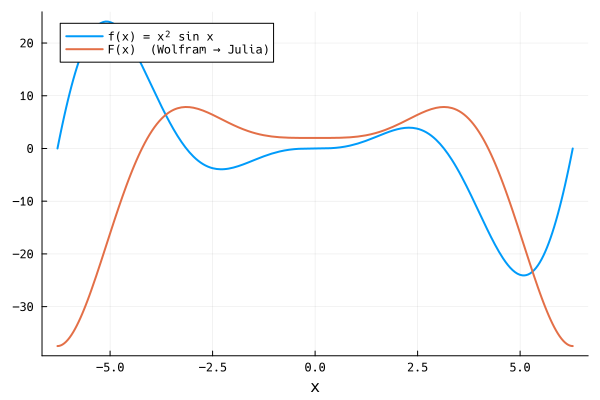

In [10]:
plot(f, -2π, 2π; label="f(x) = x² sin x", lw=2)
plot!(F, -2π, 2π; label="F(x)  (Wolfram → Julia)", lw=2, xlabel="x", legend=:topleft)

### 文字列で被積分関数を渡す版

毎回同じ手順なので 1 つの関数にまとめます。被積分関数は Wolfram 言語の文字列で渡します。
戻り値は `(Wolfram の式, Julia の関数)` です。

In [11]:
function indefinite(f::AbstractString, var::AbstractString="x")
    lhs = MathLink.parseexpr("Integrate[$f, $var]")
    Fw  = weval(lhs)
    showeq(lhs, Fw; C=true)
    return Fw, to_function(Fw, Symbol(var))
end

indefinite (generic function with 2 methods)

In [12]:
_, G1 = indefinite("1/(1 + x^2)")
_, G2 = indefinite("Sqrt[1 - x^2]")
_, G3 = indefinite("Exp[-x^2]")        # 誤差関数 erf が現れる（SpecialFunctions.erf に変換）
_, G4 = indefinite("1/(x^4 + 1)")

G1(1.0), G2(0.5), G3(1.0), G4(1.0)

(0.7853981633974483, 0.4783057387452591, 0.746824132812427, 0.866972987339911)

In [13]:
# 検算：∫₀¹ 1/(x⁴+1) dx
@show G4(1.0) - G4(0.0)
@show quadgk(x -> 1/(x^4 + 1), 0, 1)[1];

G4(1.0) - G4(0.0) = 0.866972987339911
(quadgk((x->(#= In[13]:3 =#
            1 / (x ^ 4 + 1))), 0, 1))[1] = 0.866972987339911


## 5. 定積分 → 厳密値を Julia で使う

`weval` の戻り値は

- 整数なら Julia の `Int`（そのまま使える）
- それ以外（$\sqrt{\pi}$，$\frac13$ など）は厳密な式 `WExpr`

です。`to_value` で Julia の値に直します。有理数は `Rational` として**厳密なまま**，$\pi$ などを含む場合は `Float64` になります。

In [14]:
function definite(f::AbstractString, var::AbstractString, a, b)
    lhs = MathLink.parseexpr("Integrate[$f, {$var, $a, $b}]")
    Iw  = weval(lhs)
    showeq(lhs, Iw)
    return Iw
end

definite (generic function with 1 method)

In [15]:
I1 = definite("x^2", "x", 0, 1)
v1 = to_value(I1)
@show v1 typeof(v1)             # Rational として厳密
v1 + 1//6                       # Julia の有理数演算にそのまま使える

v1 = 1//3
typeof(v1) = Rational{Int64}


1//2

In [16]:
I2 = definite("Exp[-x^2]", "x", "-Infinity", "Infinity")
v2 = to_value(I2)
@show to_expr(I2)               # sqrt(π)
@show v2
@show quadgk(x -> exp(-x^2), -Inf, Inf)[1];

to_expr(I2) = :(sqrt(π))
v2 = 1.7724538509055159
(quadgk((x->(#= In[16]:5 =#
            exp(-(x ^ 2)))), -Inf, Inf))[1] = 1.7724538509055137


In [17]:
I3 = definite("1/(x^3 + 1)", "x", 0, 1)
I4 = definite("Sin[x]/x", "x", 0, "Infinity")
I5 = definite("Log[x]^2/(1 + x^2)", "x", 0, "Infinity")
to_value.([I3, I4, I5])

3-element Vector{Float64}:
 0.8356488482647209
 1.5707963267948966
 3.875784585037477

### 厳密値を保ったまま計算を続ける／任意精度で取り出す

厳密な式 `WExpr` は Julia 側で `+ - * /` ができ，`weval` で Wolfram に簡約させられます。
高精度の数値が欲しいときは Wolfram の `N[式, 桁数]` を使い，`BigFloat` として受け取ります。

In [18]:
S = weval(W"Simplify"(I2^2 + 2 * I4))     # (√π)² + 2·(π/2) を厳密に計算

W`Times[2, Pi]`

In [19]:
# 50 桁の BigFloat として取り出す（wN は Wolfram の N[式, 桁数] を使う）
x3 = wN(I3, 50)
@show typeof(x3)
x3

typeof(x3) = BigFloat


0.8356488482647210533371034597001107667865221274843322

### パラメータを含む定積分 → パラメータの関数にする

`Assumptions` を付けると条件分岐のない結果が返ります。結果は $a$ の式なので，Julia の関数 `g(a)` にできます。

In [20]:
lhs = W`Integrate[Exp[-a x^2] Cos[x], {x, -Infinity, Infinity}, Assumptions -> a > 0]`
gw  = weval(lhs)
showtex(tex(W`HoldForm[Integrate[Exp[-a x^2] Cos[x], {x, -Infinity, Infinity}]]`) * " = " * tex(gw) * "\\quad (a>0)")

g = to_function(gw, :a)
@show g(2.0)
@show quadgk(x -> exp(-2x^2) * cos(x), -Inf, Inf)[1];

g(2.0) = 1.1060458441464132
(quadgk((x->(#= In[20]:7 =#
            exp(-2 * x ^ 2) * cos(x))), -Inf, Inf))[1] = 1.1060458441464132


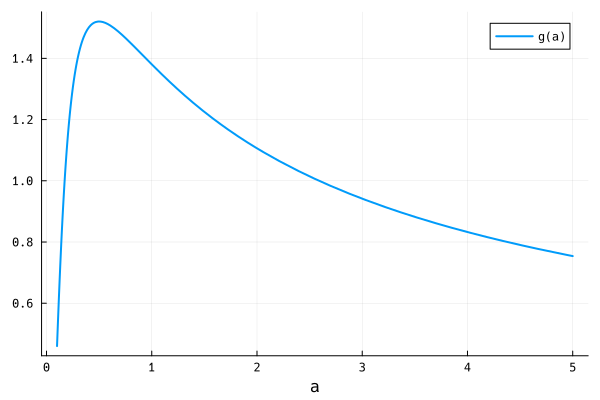

In [21]:
plot(g, 0.1, 5; lw=2, label="g(a)", xlabel="a")

## 6. Julia の値を Wolfram の式に埋め込む

``W`...` `` の中では `$変数` で Julia の値を埋め込めます。Julia のループと組み合わせられます。

In [22]:
for n in 0:5
    lhs = W`Integrate[x^$n Exp[-x], {x, 0, Infinity}]`
    showeq(lhs, weval(lhs))
end

In [23]:
# 結果を Julia の配列として集める（有理数は厳密な Rational，π を含むものは Float64 になる）
wallis = [to_value(weval(W`Integrate[Sin[x]^$n, {x, 0, Pi/2}]`)) for n in 0:8]

9-element Vector{Real}:
   1.5707963267948966
   1
   0.7853981633974483
  2//3
   0.5890486225480862
  8//15
   0.4908738521234052
 16//35
   0.4295146206079795

## 7. うまくいかないとき

- **積分が求まらない／発散する**：Wolfram は `Integrate[...]` を未評価のまま返します。`to_value` / `to_function` はエラーでそれを知らせます。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します（例：`"BesselJ" => :besselj`）。
- **LaTeX 表示を止めたい**：`MathLink.set_texOutput(false)`
- **Wolfram Engine が見つからない**：環境変数 `JULIA_MATHKERNEL`，`JULIA_MATHLINK` を設定して `Pkg.build("MathLink")`。

In [24]:
# 発散する例：Wolfram の警告のあと，to_value がエラーで知らせる
Idiv = weval(W`Integrate[1/x, {x, 0, 1}]`)
try
    to_value(Idiv)
catch e
    println(e.msg)
end

┌ Warning:                              1
│ Integrate::idiv: Integral of - does not converge on {0, 1}.
│                              x
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16


Wolfram が閉じた式で求められませんでした（発散する，解けない，など）: W`Integrate[Power[x, -1], List[x, 0, 1]]`
